In [1]:
import os
import cv2
import pywt
import numpy as np
import tensorflow as tf

from tensorflow.keras import layers

from tensorflow.keras.models import Model
from tensorflow.keras.utils import Sequence

from tfkan.layers import DenseKAN

In [2]:
IMG_SIZE = 255
BATCH_SIZE = 32
EPOCHS = 50

DATASET = r"C:\Users\shuvo\Desktop\BR35H"


In [3]:
def wavelet_transform(image):

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    coeffs2 = pywt.dwt2(gray, 'haar')

    LL, (LH, HL, HH) = coeffs2

    LL = cv2.resize(LL,(255,255))
    LH = cv2.resize(LH,(255,255))
    HL = cv2.resize(HL,(255,255))
    HH = cv2.resize(HH,(255,255))

    wavelet = np.stack([LL,LH,HL,HH],axis=-1)

    wavelet = wavelet.astype(np.float32)

    wavelet = (wavelet-wavelet.min())/(wavelet.max()-wavelet.min()+1e-8)

    return wavelet

In [4]:
class BrainDataset(Sequence):

    def __init__(self, image_paths, labels, batch_size=16, shuffle=True):

        self.image_paths = image_paths
        self.labels = labels
        self.batch = batch_size
        self.shuffle = shuffle

    def __len__(self):
        return int(np.ceil(len(self.image_paths) / self.batch))

    def __getitem__(self, idx):

        batch_paths = self.image_paths[idx*self.batch:(idx+1)*self.batch]
        batch_labels = self.labels[idx*self.batch:(idx+1)*self.batch]

        original = []
        wavelet = []

        for path in batch_paths:

            img = cv2.imread(path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (255,255))

            # ======================================
            # Horizontal Flip (Training Only)
            # ======================================
            if self.shuffle:
                if np.random.rand() < 0.5:
                    img = cv2.flip(img, 1)

            # Normalize
            img = img.astype(np.float32) / 255.0

            # Generate Wavelet from the (possibly flipped) image
            wav = wavelet_transform((img * 255).astype(np.uint8))

            original.append(img)
            wavelet.append(wav)

        return (
            {
                "original": np.array(original, dtype=np.float32),
                "wavelet": np.array(wavelet, dtype=np.float32)
            },
            np.array(batch_labels, dtype=np.float32)
        )

    def on_epoch_end(self):
        if self.shuffle:
            idx = np.arange(len(self.image_paths))
            np.random.shuffle(idx)

            self.image_paths = np.array(self.image_paths)[idx].tolist()
            self.labels = np.array(self.labels)[idx].tolist()

In [5]:
images=[]
labels=[]

for cls in ['0','1']:

    folder=os.path.join(DATASET,cls)

    for file in os.listdir(folder):

        images.append(os.path.join(folder,file))
        labels.append(int(cls))

In [6]:
from sklearn.model_selection import train_test_split

train_x,test_x,train_y,test_y=train_test_split(

    images,
    labels,
    test_size=0.2,
    stratify=labels,
    random_state=42
)

In [7]:
train_generator = BrainDataset(
    train_x,
    train_y,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_generator = BrainDataset(
    test_x,
    test_y,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [8]:
original_input=layers.Input(
    shape=(255,255,3),
    name="original"
)

x=layers.Conv2D(32,3,padding="same",activation="relu")(original_input)
x=layers.MaxPooling2D()(x)

x=layers.Conv2D(64,3,padding="same",activation="relu")(x)
x=layers.MaxPooling2D()(x)

x=layers.Conv2D(128,3,padding="same",activation="relu")(x)
x=layers.MaxPooling2D()(x)

x=layers.Conv2D(256,3,padding="same",activation="relu")(x)
x=layers.MaxPooling2D()(x)

x=layers.Conv2D(512,3,padding="same",activation="relu")(x)
x=layers.MaxPooling2D()(x)

x=layers.Conv2D(1024,3,padding="same",activation="relu")(x)
x=layers.GlobalAveragePooling2D()(x)

original_features=layers.Dense(256,activation="relu")(x)

In [9]:
wavelet_input=layers.Input(
    shape=(255,255,4),
    name="wavelet"
)

y=layers.Conv2D(32,3,padding="same",activation="relu")(wavelet_input)
y=layers.MaxPooling2D()(y)

y=layers.Conv2D(64,3,padding="same",activation="relu")(y)
y=layers.MaxPooling2D()(y)

y=layers.Conv2D(128,3,padding="same",activation="relu")(y)
y=layers.MaxPooling2D()(y)

y=layers.Conv2D(256,3,padding="same",activation="relu")(y)
y=layers.MaxPooling2D()(y)

y=layers.Conv2D(512,3,padding="same",activation="relu")(y)
y=layers.MaxPooling2D()(y)

y=layers.Conv2D(1024,3,padding="same",activation="relu")(y)
y=layers.GlobalAveragePooling2D()(y)


wavelet_features=layers.Dense(256,activation="relu")(y)

In [10]:
fusion=layers.Concatenate()(
    [
        original_features,
        wavelet_features
    ]
)

In [11]:
fusion = DenseKAN(256)(fusion)
fusion = layers.Dropout(0.2)(fusion)

fusion = DenseKAN(128)(fusion)
fusion = layers.Dropout(0.2)(fusion)

fusion = DenseKAN(64)(fusion)

output = layers.Dense(1, activation="sigmoid")(fusion)

In [12]:
model=Model(

    inputs=[original_input,wavelet_input],
    outputs=output
)

model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 original (InputLayer)          [(None, 255, 255, 3  0           []                               
                                )]                                                                
                                                                                                  
 wavelet (InputLayer)           [(None, 255, 255, 4  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 255, 255, 32  896         ['original[0][0]']               
                                )                                                             

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(),
        tf.keras.metrics.Recall(),
        tf.keras.metrics.AUC()
    ]
)

In [14]:
callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        "best.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max"
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True
    )
]

In [15]:
history=model.fit(

    train_generator,

    validation_data=test_generator,

    epochs=45,

    callbacks=callbacks
)

Epoch 1/45
75/75 [==============================] - 25s 209ms/step - loss: 0.6730 - accuracy: 0.5746 - precision: 0.5654 - recall: 0.6478 - auc: 0.6173 - val_loss: 0.6056 - val_accuracy: 0.6733 - val_precision: 0.6711 - val_recall: 0.6800 - val_auc: 0.7505 - lr: 1.0000e-04
Epoch 2/45
75/75 [==============================] - 12s 164ms/step - loss: 0.5692 - accuracy: 0.7029 - precision: 0.7027 - recall: 0.7044 - auc: 0.7756 - val_loss: 0.5356 - val_accuracy: 0.7350 - val_precision: 0.7183 - val_recall: 0.7733 - val_auc: 0.8041 - lr: 1.0000e-04
Epoch 3/45
75/75 [==============================] - 12s 164ms/step - loss: 0.5218 - accuracy: 0.7483 - precision: 0.7226 - recall: 0.8068 - auc: 0.8128 - val_loss: 0.5175 - val_accuracy: 0.7367 - val_precision: 0.7233 - val_recall: 0.7667 - val_auc: 0.8210 - lr: 1.0000e-04
Epoch 4/45
75/75 [==============================] - 12s 163ms/step - loss: 0.5012 - accuracy: 0.7596 - precision: 0.7254 - recall: 0.8360 - auc: 0.8283 - val_loss: 0.4960 - val_a

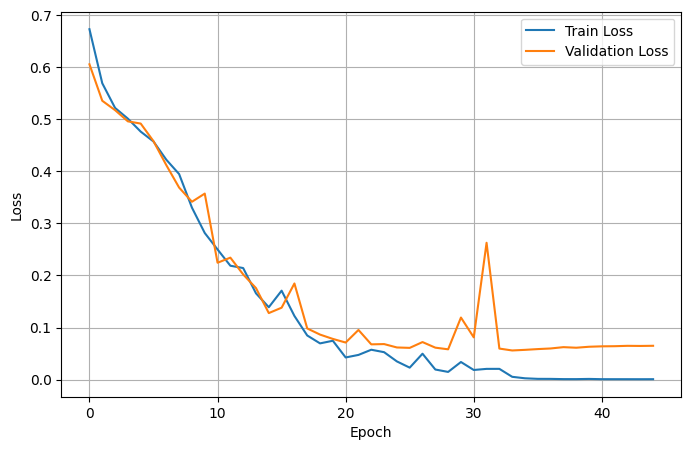

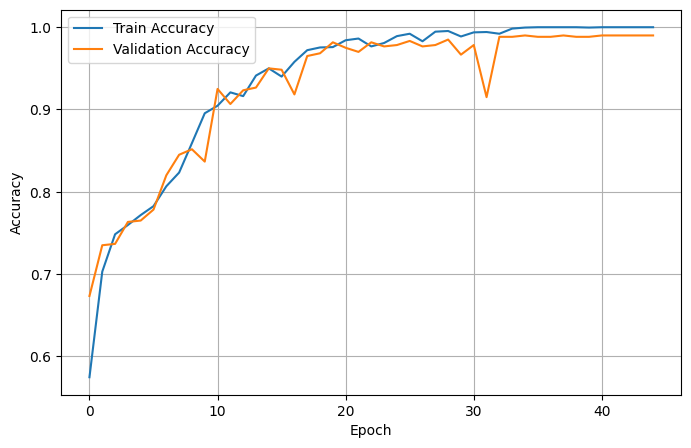

19/19 [==============================] - 3s 125ms/step


In [16]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)



# PLOT LOSS
# =====================================================

plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# =====================================================
# PLOT ACCURACY
# =====================================================

plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# =====================================================
# TEST EVALUATION
# =====================================================

y_true = np.array(test_y)

y_prob = model.predict(test_generator).ravel()

y_pred = (y_prob > 0.5).astype(int)

<Figure size 600x600 with 0 Axes>

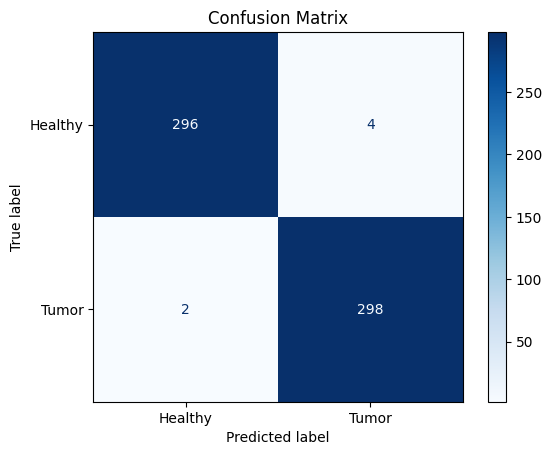

Wrong Predictions : 6


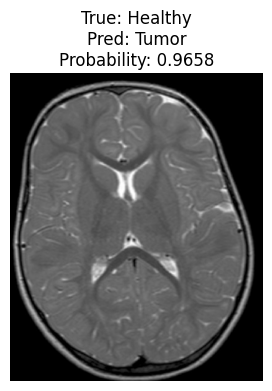

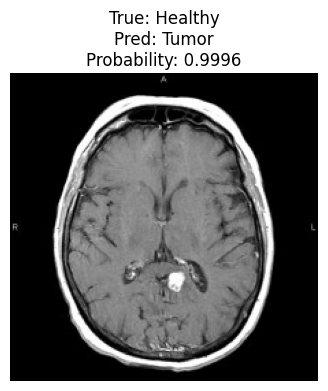

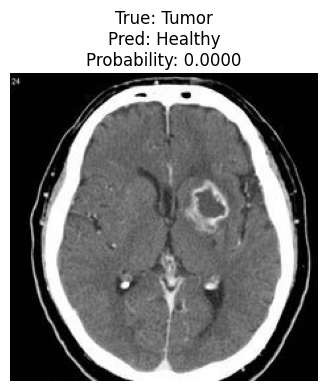

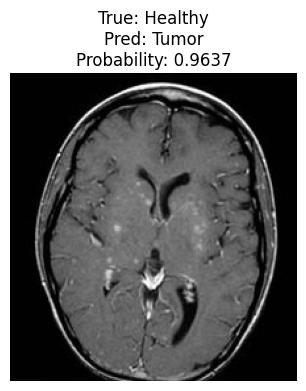

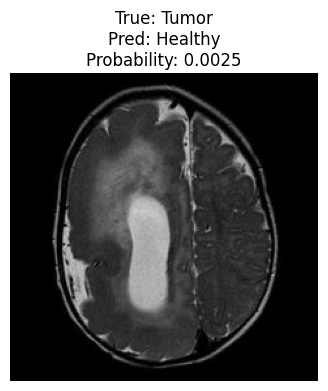

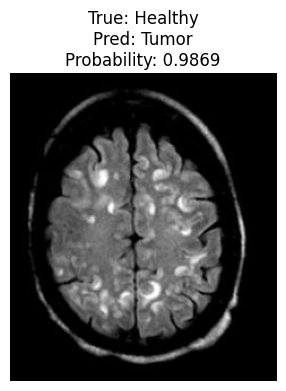

In [17]:
import numpy as np

y_true = []
y_pred = []
y_prob = []

for i in range(len(test_generator)):

    x_batch, y_batch = test_generator[i]

    pred = model.predict(x_batch, verbose=0)

    y_true.extend(y_batch)

    y_prob.extend(pred.flatten())

    y_pred.extend((pred > 0.5).astype(int).flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy","Tumor"]
)

plt.figure(figsize=(6,6))
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()



wrong = np.where(y_true != y_pred)[0]

print("Wrong Predictions :", len(wrong))


import matplotlib.pyplot as plt

for idx in wrong[:20]:

    img_path = test_x[idx]

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(4,4))
    plt.imshow(img)
    plt.axis("off")

    plt.title(
        f"True: {'Tumor' if y_true[idx] else 'Healthy'}\n"
        f"Pred: {'Tumor' if y_pred[idx] else 'Healthy'}\n"
        f"Probability: {y_prob[idx]:.4f}"
    )

    plt.show()



In [18]:
for idx in wrong:

    print(test_x[idx])

C:\Users\shuvo\Desktop\BR35H\1\y1382.jpg
C:\Users\shuvo\Desktop\BR35H\0\no520.jpg
C:\Users\shuvo\Desktop\BR35H\0\no426.jpg
C:\Users\shuvo\Desktop\BR35H\0\no307.jpg
C:\Users\shuvo\Desktop\BR35H\0\no265.jpg
C:\Users\shuvo\Desktop\BR35H\0\no1359.jpg
C:\Users\shuvo\Desktop\BR35H\0\no1414.jpg
C:\Users\shuvo\Desktop\BR35H\0\no978.jpg
C:\Users\shuvo\Desktop\BR35H\0\no916.jpg
C:\Users\shuvo\Desktop\BR35H\1\y724.jpg
C:\Users\shuvo\Desktop\BR35H\1\y1464.jpg
C:\Users\shuvo\Desktop\BR35H\0\no669.jpg
C:\Users\shuvo\Desktop\BR35H\0\no378.jpg
C:\Users\shuvo\Desktop\BR35H\0\no704.jpg
C:\Users\shuvo\Desktop\BR35H\0\no1182.jpg
C:\Users\shuvo\Desktop\BR35H\0\no720.jpg
C:\Users\shuvo\Desktop\BR35H\0\no1344.jpg
C:\Users\shuvo\Desktop\BR35H\0\no554.jpg
C:\Users\shuvo\Desktop\BR35H\1\y933.jpg
C:\Users\shuvo\Desktop\BR35H\0\no448.jpg
C:\Users\shuvo\Desktop\BR35H\0\no752.jpg
C:\Users\shuvo\Desktop\BR35H\0\no519.jpg
C:\Users\shuvo\Desktop\BR35H\0\no1360.jpg
C:\Users\shuvo\Desktop\BR35H\1\y1463.jpg
C:\Users\shuv

In [18]:
loss, accuracy, precision, recall, auc_score = model.evaluate(test_generator)

print("\n" + "="*50)
print("Test Results")
print("="*50)

print(f"Test Accuracy : {accuracy:.4f}")
print(f"Test Loss     : {loss:.4f}")
print(f"Precision     : {precision:.4f}")
print(f"Recall        : {recall:.4f}")
print(f"AUC           : {auc_score:.4f}")

19/19 [==============================] - 3s 115ms/step - loss: 0.0649 - accuracy: 0.9900 - precision: 0.9868 - recall: 0.9933 - auc: 0.9945

Test Results
Test Accuracy : 0.9900
Test Loss     : 0.0649
Precision     : 0.9868
Recall        : 0.9933
AUC           : 0.9945


In [17]:
import os

weights_path = r"D:\BrainTumor\Model\BR35H_Final_Final.h5"

os.makedirs(os.path.dirname(weights_path), exist_ok=True)

model.save_weights(weights_path)

print("Weights saved successfully!")
print("Location:", weights_path)

Weights saved successfully!
Location: D:\BrainTumor\Model\BR35H_Final_Final.h5


In [19]:
model.save("D:\BrainTumor\Model\BR35H_Final_Final_11.h5")

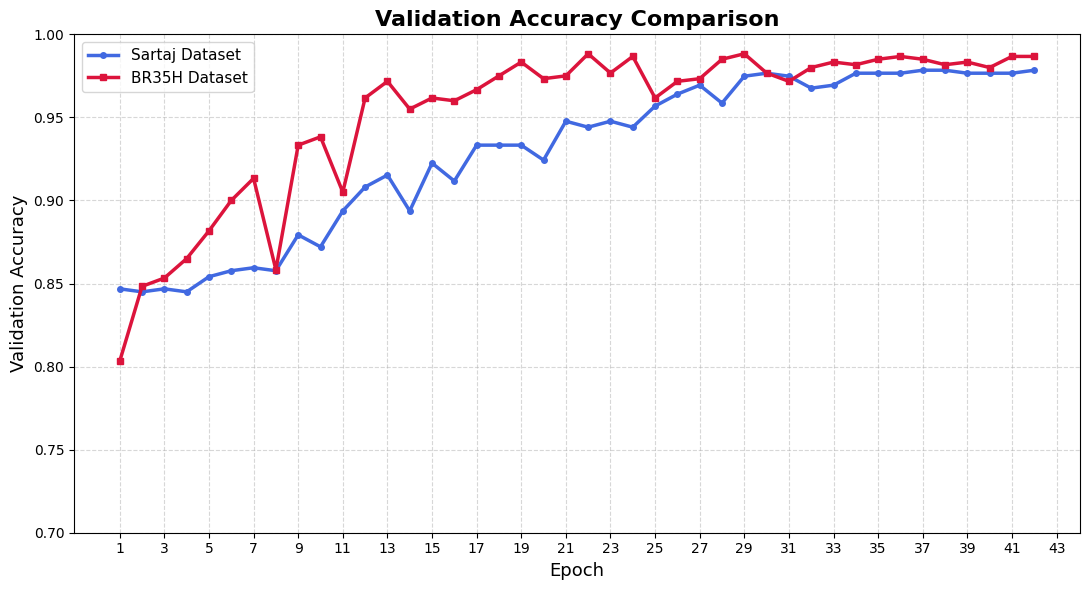

In [1]:
import matplotlib.pyplot as plt

# ==========================================================
# Validation Accuracy Comparison (50 Epochs)
# ==========================================================

# Sartaj Dataset
sartaj_val_acc = [
    0.8468, 0.8450, 0.8468, 0.8450, 0.8541,
    0.8577, 0.8595, 0.8577, 0.8793, 0.8721,
    0.8937, 0.9081, 0.9153, 0.8937, 0.9225,
    0.9117, 0.9333, 0.9333, 0.9333, 0.9243,
    0.9477, 0.9441, 0.9477, 0.9441, 0.9568,
    0.9640, 0.9694, 0.9586, 0.9748, 0.9766,
    0.9748, 0.9676, 0.9694, 0.9766, 0.9766,
    0.9766, 0.9784, 0.9784, 0.9766, 0.9766,
    0.9766, 0.9784
]

# BR35H Dataset
br35h_val_acc = [
    0.8033, 0.8483,
    0.8533, 0.8650, 0.8817, 0.9000, 0.9133,
    0.8583, 0.9333, 0.9383, 0.9050, 0.9617,
    0.9717, 0.9550, 0.9617, 0.9600, 0.9667,
    0.9750, 0.9833, 0.9733, 0.9750, 0.9883,
    0.9767, 0.9867, 0.9617, 0.9717, 0.9733,
    0.9850, 0.9883, 0.9767, 0.9717, 0.9800,
    0.9833, 0.9817, 0.9850, 0.9867, 0.9850,
    0.9817, 0.9833, 0.9800, 0.9867, 0.9867
]

epochs_sartaj = range(1, len(sartaj_val_acc) + 1)
epochs_br35h = range(1, len(br35h_val_acc) + 1)

plt.figure(figsize=(11,6))

plt.plot(
    epochs_sartaj,
    sartaj_val_acc,
    color="royalblue",
    marker="o",
    linewidth=2.5,
    markersize=4,
    label="Sartaj Dataset"
)

plt.plot(
    epochs_br35h,
    br35h_val_acc,
    color="crimson",
    marker="s",
    linewidth=2.5,
    markersize=4,
    label="BR35H Dataset"
)

plt.title("Validation Accuracy Comparison", fontsize=16, fontweight="bold")
plt.xlabel("Epoch", fontsize=13)
plt.ylabel("Validation Accuracy", fontsize=13)

plt.xticks(range(1, 45, 2))
plt.yticks([0.70,0.75,0.80,0.85,0.90,0.95,1.00])

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

Classification Report
              precision    recall  f1-score   support

     Healthy       0.99      0.99      0.99       300
       Tumor       0.99      0.99      0.99       300

    accuracy                           0.99       600
   macro avg       0.99      0.99      0.99       600
weighted avg       0.99      0.99      0.99       600



<Figure size 600x600 with 0 Axes>

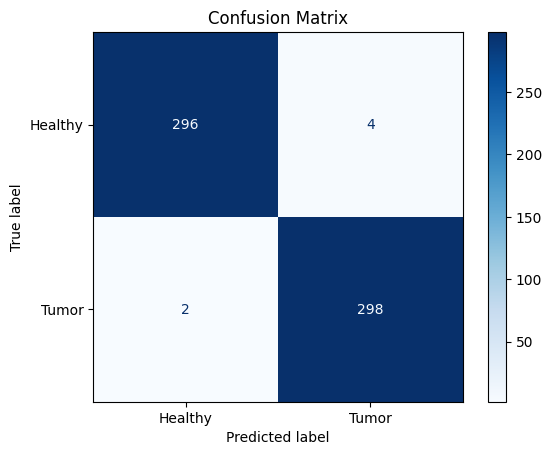

Classification Report
              precision    recall  f1-score   support

     Healthy       0.99      0.99      0.99       300
       Tumor       0.99      0.99      0.99       300

    accuracy                           0.99       600
   macro avg       0.99      0.99      0.99       600
weighted avg       0.99      0.99      0.99       600



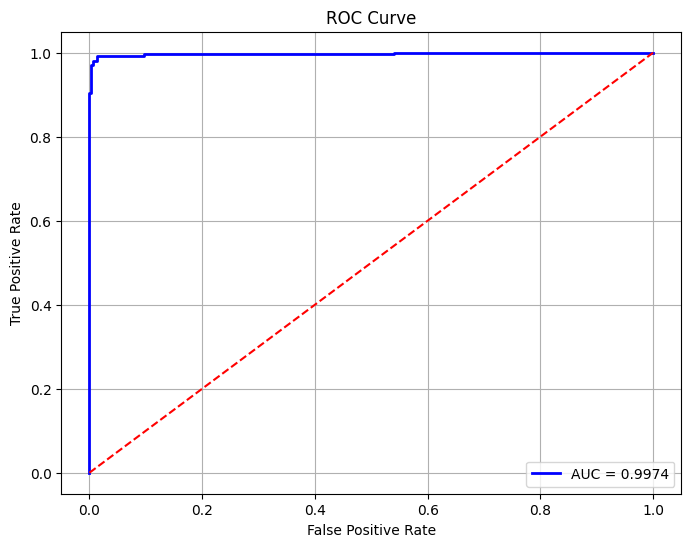

ROC-AUC Score : 0.9974111111111111


In [20]:
print("="*60)
print("Classification Report")
print("="*60)

print(classification_report(
    y_true,
    y_pred,
    target_names=["Healthy","Tumor"]
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy","Tumor"]
)

disp.plot(cmap='Blues', values_format='d')

plt.title("Confusion Matrix")
plt.show()

print("="*60)
print("Classification Report")
print("="*60)

print(classification_report(
    y_true,
    y_pred,
    target_names=["Healthy","Tumor"]
))
fpr, tpr, thresholds = roc_curve(y_true, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8,6))

plt.plot(fpr, tpr,
         color='blue',
         linewidth=2,
         label='AUC = %0.4f' % roc_auc)

plt.plot([0,1],[0,1],
         color='red',
         linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')

plt.legend(loc='lower right')
plt.grid(True)

plt.show()

print("ROC-AUC Score :", roc_auc)

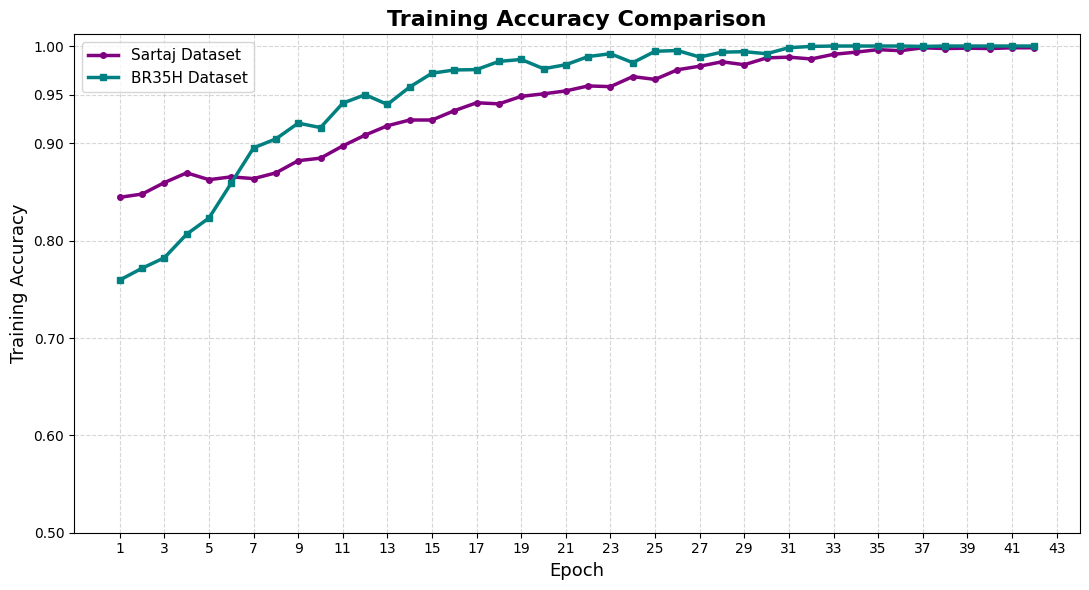

In [21]:
import matplotlib.pyplot as plt


# ==========================================================
# Training Accuracy Comparison
# ==========================================================


# -----------------------------
# Sartaj Training Accuracy
# -----------------------------

sartaj_train_acc = [

0.8446,0.8479,0.8597,0.8697,0.8627,
0.8656,0.8638,0.8697,0.8822,0.8848,
0.8974,0.9085,0.9181,0.9240,0.9240,
0.9336,0.9417,0.9406,0.9483,0.9509,
0.9539,0.9590,0.9583,0.9686,0.9657,
0.9756,0.9793,0.9838,0.9808,0.9878,
0.9886,0.9867,0.9915,0.9937,0.9963,
0.9952,0.9982,0.9974,0.9978,0.9974,
0.9982,0.9982

]


# -----------------------------
# BR35H Training Accuracy
# -----------------------------

br35h_train_acc = [

0.7596,0.7717,
0.7825,0.8067,0.8233,0.8592,0.8954,
0.9046,0.9208,0.9162,0.9413,0.9500,
0.9400,0.9579,0.9721,0.9754,0.9758,
0.9842,0.9862,0.9767,0.9808,0.9892,
0.9921,0.9829,0.9946,0.9954,0.9887,
0.9937,0.9942,0.9921,0.9983,0.9996,
1.0000,1.0000,1.0000,1.0000,0.9996,
1.0000,1.0000,1.0000,1.0000,1.0000

]


# Epoch numbers

epochs_sartaj = range(
    1,
    len(sartaj_train_acc)+1
)

epochs_br35h = range(
    1,
    len(br35h_train_acc)+1
)



# ==========================================================
# Plot
# ==========================================================

plt.figure(figsize=(11,6))


plt.plot(

    epochs_sartaj,

    sartaj_train_acc,

    color="purple",

    marker="o",

    linewidth=2.5,

    markersize=4,

    label="Sartaj Dataset"

)



plt.plot(

    epochs_br35h,

    br35h_train_acc,

    color="teal",

    marker="s",

    linewidth=2.5,

    markersize=4,

    label="BR35H Dataset"

)



plt.title(
    "Training Accuracy Comparison",
    fontsize=16,
    fontweight="bold"
)


plt.xlabel(
    "Epoch",
    fontsize=13
)


plt.ylabel(
    "Training Accuracy",
    fontsize=13
)



plt.xticks(
    range(1,45,2)
)


plt.yticks(
    [0.50,0.60,0.70,0.80,0.90,0.95,1.00]
)



plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)


plt.legend(
    fontsize=11
)



plt.tight_layout()

plt.show()